# Estimación de la posición: de las pseudodistancias a X, Y, Z y el reloj del receptor

Este cuaderno continúa `gnss_pseudodistancia.ipynb`. Allí se dedujo la ecuación de la pseudodistancia y, con la posición de la estación conocida, se estimó el desfase del reloj del receptor. Aquí la posición es la incógnita: con las pseudodistancias reales de la estación **BOGT** (Bogotá, red IGS, NASA/JPL) del 15 de septiembre de 2026 se calcula, paso a paso, dónde está el receptor: linealización, mínimos cuadrados, iteración, ponderación, covarianza y DOP. Cada resultado se compara con la posición de referencia de la estación.

**Datos.** La sección 0 de `gnss_pseudodistancia.ipynb` lee los archivos RINEX y guarda dos archivos en `data/`:

- `bogt_20260915_gps.csv`: la tabla `D`, una fila por época y satélite GPS: `P1` (pseudodistancia con el código C/A en L1, m), `xs, ys, zs` (posición del satélite en el instante de emisión, m), `dts` (desfase del reloj del satélite, $\delta t^s$, ya ajustado con su retardo de grupo $T_{GD}$, s), `el`, `az` (elevación y acimut desde BOGT, grados), más `P2`, `L1` y `S1`, que aquí no se usan.
- `bogt_20260915_estacion.txt`: la **posición de referencia** de la estación, la del encabezado RINEX (`APPROX POSITION XYZ`). Es aproximada, al metro o mejor, así que errores de menos de un metro no se pueden juzgar con ella.

**Notación.** La misma de `gnss_pseudodistancia.ipynb` (tabla de su sección 0):

| símbolo | qué es |
|---|---|
| $P1_i$ | pseudodistancia medida al satélite $i$ |
| $(X, Y, Z)$ | posición del receptor: las incógnitas |
| $(x^s_i, y^s_i, z^s_i)$ | posición del satélite $i$ en el instante de emisión |
| $r_i$ | distancia geométrica entre el receptor y el satélite $i$ |
| $c\,\delta t_R$ | desfase del reloj del receptor, en metros: la cuarta incógnita |
| $c\,\delta t^s_i$ | desfase del reloj del satélite $i$, en metros; lo transmite el satélite |
| $T_i$, $I_i$ | retardos troposférico e ionosférico; aquí no se modelan |
| $\varepsilon_i$ | lo que no se modela: ruido, multitrayectoria y, en este cuaderno, también $T_i + I_i$ |

Cada sección sigue el mismo patrón: una definición, las ecuaciones paso a paso, el cálculo con los datos y, cuando ayuda, una figura con su lectura.


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
AZUL, ROJO, VERDE, GRIS, NARANJA = "#1F3864", "#9C0006", "#375623", "#7F7F7F", "#C55A11"

# velocidad de la luz en el vacío (m/s): valor exacto, porque define el metro en el SI
C = 299792458.0

# la tabla D de gnss_pseudodistancia.ipynb (sección 0): una fila por época y satélite GPS
D = pd.read_csv("data/bogt_20260915_gps.csv", parse_dates=["t"])

# la posición de referencia de la estación: la aproximada del encabezado RINEX (X, Y, Z geocéntricas, m)
lineas = open("data/bogt_20260915_estacion.txt").read().splitlines()[1:]
est = dict(linea.split() for linea in lineas)
rx = np.array([float(est["X"]), float(est["Y"]), float(est["Z"])])

print("filas:", len(D), "| épocas:", D.t.nunique(), "| satélites distintos:", D.sv.nunique())
print("BOGT, posición de referencia (X, Y, Z) =", rx)
D.head()

filas: 27312 | épocas: 2880 | satélites distintos: 32
BOGT, posición de referencia (X, Y, Z) = [ 1744399.0397 -6116037.5577   512731.7532]


,t,sv,P1,P2,L1,S1,xs,ys,zs,dts,el,az
0,2026-09-15,G01,2.286695e+07,2.286696e+07,1.201667e+08,43.00,7.296331e+06,-1.744863e+07,-1.861866e+07,0.000172,28.206252,173.658860
1,2026-09-15,G02,2.136431e+07,2.136431e+07,1.122703e+08,46.00,1.350578e+07,-1.873477e+07,-1.218097e+07,0.000176,41.829773,150.537422
2,2026-09-15,G03,2.381813e+07,2.381813e+07,1.251650e+08,41.25,-4.519559e+06,-1.798759e+07,-1.925986e+07,0.000267,19.727789,204.363168
3,2026-09-15,G04,2.035627e+07,2.035627e+07,1.069731e+08,48.50,2.989410e+05,-2.631631e+07,2.755613e+06,0.000065,70.010475,275.735921
4,2026-09-15,G08,2.000519e+07,2.000520e+07,1.051282e+08,50.50,5.720878e+06,-2.429087e+07,8.143931e+06,0.000346,72.001567,349.230971


## 1. Planteamiento: ecuaciones de observación y cuatro incógnitas

Se parte de la ecuación de la pseudodistancia de `gnss_pseudodistancia.ipynb`, para el satélite $i$:
$$P1_i = r_i + c\,\delta t_R - c\,\delta t^s_i + T_i + I_i + \varepsilon_i$$
Allí la posición de la estación era conocida y $r_i$ era un dato. Aquí no: $r_i$ depende de las incógnitas.

| término | ¿se conoce? | por qué |
|---|---|---|
| $P1_i$ | sí | lo midió el receptor |
| $c\,\delta t^s_i$ | sí | lo transmite el satélite (columna `dts`) |
| $x^s_i, y^s_i, z^s_i$ | sí | se calculan con las efemérides |
| $X, Y, Z$ | **no** | es lo que se busca |
| $c\,\delta t_R$ | **no** | es la cuarta incógnita |
| $T_i$, $I_i$ | no se modelan | se dejan dentro de $\varepsilon_i$; la sección 9 muestra su efecto |

Pasando lo conocido a la izquierda:
$$\underbrace{P1_i + c\,\delta t^s_i}_{\text{medida corregida}} = \underbrace{\sqrt{(X - x^s_i)^2 + (Y - y^s_i)^2 + (Z - z^s_i)^2}}_{r_i(X,\,Y,\,Z)} + c\,\delta t_R + \varepsilon_i$$
Es la ecuación de la sección 12 de `gnss_pseudodistancia.ipynb`, sin los términos de atmósfera. Hay una por satélite (nueve a las 12:00) y cuatro incógnitas. La raíz cuadrada impide despejar, y con nueve ecuaciones y ruido no existe un $(X, Y, Z, c\,\delta t_R)$ que las cumpla todas. Hace falta (1) un método que se acerque a la solución paso a paso y (2) un criterio para elegir la «mejor» cuando ninguna es exacta.


In [2]:
t0 = pd.Timestamp("2026-09-15 12:00:00")
ep = D[D.t == t0].sort_values("sv").reset_index(drop=True)

S = ep[["xs", "ys", "zs"]].values           # posiciones de los satélites en el instante de emisión: matriz n × 3 (m)
P = ep.P1.values + C * ep.dts.values         # medida corregida P1 + c·δtˢ (m)
n = len(P)
print("satélites:", list(ep.sv), "| n =", n)

tabla = ep[["sv", "el", "P1"]].copy()
tabla["c·δtˢ (m)"] = C * ep.dts
tabla["P1 + c·δtˢ (m)"] = P
tabla.round(3)


satélites: ['G05', 'G11', 'G12', 'G13', 'G15', 'G20', 'G24', 'G25', 'G29'] | n = 9


,sv,el,P1,c·δtˢ (m),P1 + c·δtˢ (m)
0,G05,22.068,2.342492e+07,-70984.934,2.335393e+07
1,G11,29.830,2.281779e+07,-62718.618,2.275507e+07
2,G12,22.278,2.386724e+07,-180485.335,2.368675e+07
3,G13,19.560,2.365321e+07,132652.265,2.378587e+07
4,G15,68.513,2.022137e+07,133372.634,2.035474e+07
5,G20,46.896,2.149660e+07,85762.858,2.158236e+07
6,G24,40.558,2.206766e+07,62539.257,2.213020e+07
7,G25,17.461,2.412188e+07,116446.638,2.423833e+07
8,G29,47.305,2.149618e+07,-72763.214,2.142342e+07


## 2. Valor inicial: el receptor en el centro de la Tierra

Se supone que el receptor arranca en $(0, 0, 0)$ con su reloj sin desfase ($c\,\delta t_R = 0$). Desde ahí, la distancia calculada a cada satélite es su radio orbital. La diferencia entre lo medido y lo calculado se llama **observado menos calculado** ($O - C$). Aquí es de miles de kilómetros, y es la información con la que se trabaja: dice hacia dónde y cuánto mover la posición supuesta.


In [3]:
x0 = np.zeros(4)                                  # posición supuesta (X, Y, Z) = (0, 0, 0) y c·δt_R = 0
r0 = np.linalg.norm(S - x0[:3], axis=1)          # distancia de cada satélite a la posición supuesta
dP = P - (r0 + x0[3])                             # O − C: lo que la posición supuesta no explica de cada medida

pd.DataFrame({"sv": ep.sv,
              "P1 + c·δtˢ (km)": P / 1e3,
              "calculada desde (0, 0, 0) (km)": r0 / 1e3,
              "O − C (km)": dP / 1e3}).round(1)


,sv,P1 + c·δtˢ (km),"calculada desde (0, 0, 0) (km)",O − C (km)
0,G05,23353.9,26418.7,-3064.7
1,G11,22755.1,26513.3,-3758.2
2,G12,23686.8,26767.7,-3080.9
3,G13,23785.9,26612.9,-2827.1
4,G15,20354.7,26394.8,-6040.1
5,G20,21582.4,26598.9,-5016.5
6,G24,22130.2,26724.4,-4594.2
7,G25,24238.3,26853.6,-2615.3
8,G29,21423.4,26467.8,-5044.4


## 3. Método de Newton-Raphson en una dimensión

> **Newton-Raphson** — para hallar $x$ tal que $f(x) = 0$, desde una estimación $x_k$ se sustituye la curva por su recta tangente y se toma el cruce de la tangente con el eje como estimación siguiente:
> $$x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$$

Cada paso se acerca más a la raíz y, cerca de ella, aproximadamente duplica el número de cifras correctas. Con cuatro incógnitas la «tangente» es un hiperplano en cuatro dimensiones, pero la mecánica es idéntica: **evaluar, derivar, corregir, repetir**.

In [4]:
def f(x):  return x**3 - x - 1        # la función cuya raíz se busca
def df(x): return 3 * x**2 - 1        # su derivada

xk = 1.0                              # estimación inicial
filas = []
for k in range(1, 6):
    x_siguiente = xk - f(xk) / df(xk)                    # el paso de Newton-Raphson
    filas.append(dict(k=k, x_k=xk, f=f(xk), df=df(xk), x_siguiente=x_siguiente))
    xk = x_siguiente
pd.DataFrame(filas).round(7)

,k,x_k,f,df,x_siguiente
0,1,1.000000,-1.000000e+00,2.000000,1.500000
1,2,1.500000,8.750000e-01,5.750000,1.347826
2,3,1.347826,1.006822e-01,4.449905,1.325200
3,4,1.325200,2.058400e-03,4.268468,1.324718
4,5,1.324718,9.000000e-07,4.264635,1.324718


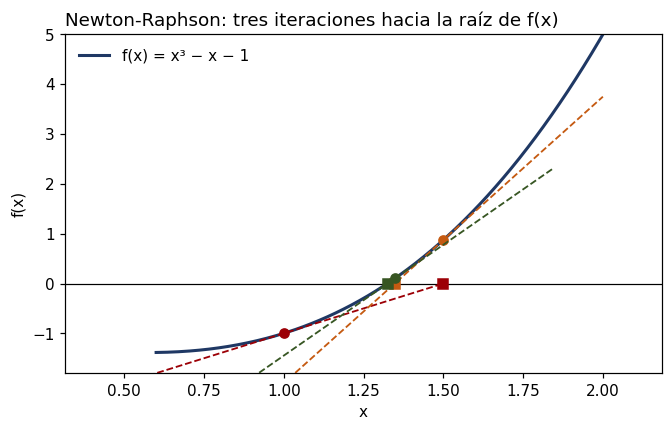

In [5]:
xs = np.linspace(0.6, 2.1, 300)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(xs, f(xs), color=AZUL, lw=2, label="f(x) = x³ − x − 1")
ax.axhline(0, color="k", lw=0.8)

xk = 1.0
for color in [ROJO, NARANJA, VERDE]:
    xt = np.linspace(xk - 0.6, xk + 0.5, 50)
    ax.plot(xt, f(xk) + df(xk) * (xt - xk), "--", color=color, lw=1.2)   # la recta tangente en xk
    ax.plot(xk, f(xk), "o", color=color)                                  # el punto sobre la curva
    xk = xk - f(xk) / df(xk)                                              # el cruce de la tangente con el eje
    ax.plot(xk, 0, "s", color=color)
ax.set_ylim(-1.8, 5)
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(frameon=False)
ax.set_title("Newton-Raphson: tres iteraciones hacia la raíz de f(x)", loc="left");

## 4. Linealización: vector unitario del receptor al satélite

> Si el receptor está en una posición aproximada $\mathbf{X}_0$ y la verdadera es $\mathbf{X}_0 + \Delta\mathbf{X}$, la distancia a un satélite en $\mathbf{x}^s$, desarrollada en **serie de Taylor a primer orden**, es
> $$r(\mathbf{X}) \approx r_0 - \mathbf{e}\cdot\Delta\mathbf{X}, \qquad \mathbf{e} = \frac{\mathbf{x}^s - \mathbf{X}_0}{r_0}$$
> $\mathbf{e}$ es el **vector unitario** del receptor hacia el satélite; sus componentes son las derivadas de la distancia respecto a $X, Y, Z$, con signo menos. Moverse 1 m hacia el satélite acorta la distancia 1 m; moverse en perpendicular no la cambia.


In [6]:
def vectores_unitarios(x, S):
    """Desde la posición x = (X, Y, Z, c·δt_R): distancias r a cada satélite y vectores unitarios e hacia cada uno."""
    r = np.linalg.norm(S - x[:3], axis=1)   # distancia a cada satélite (n)
    e = (S - x[:3]) / r[:, None]             # (satélite − receptor) / distancia: longitud 1 (n × 3)
    return e, r

# para ver los números, desde la posición de referencia de BOGT (con c·δt_R = 0)
e, r = vectores_unitarios(np.r_[rx, 0.0], S)
k15 = list(ep.sv).index("G15")
print("e(G15) =", e[k15].round(4), "| longitud =", np.linalg.norm(e[k15]).round(6), "| r0 =", f"{r[k15]:,.3f} m".replace(",", " "))

e(G15) = [ 0.0028 -0.9416  0.3368] | longitud = 1.0 | r0 = 20 354 736.807 m


## 5. Matriz de diseño

Se sustituye la linealización en la ecuación de cada satélite y se pasa lo conocido a la izquierda. Para el satélite $i$, con la posición aproximada $\mathbf{X}_0$ y el reloj aproximado $c\,\delta t_{R,0}$:
$$\underbrace{P1_i + c\,\delta t^s_i - r_{0,i} - c\,\delta t_{R,0}}_{(O - C)_i} = -e_{X,i}\,\Delta X - e_{Y,i}\,\Delta Y - e_{Z,i}\,\Delta Z + \Delta(c\,\delta t_R)$$
El lado izquierdo es el **observado menos calculado** ($O - C$, o residuo previo al ajuste): la medida corregida menos lo que predice la posición aproximada. Si esa posición es la de referencia y $c\,\delta t_{R,0} = 0$, es exactamente el *residuo de pseudodistancia* de la sección 7 de `gnss_pseudodistancia.ipynb`.

> **Matriz de diseño $\mathbf{A}$** ($n \times 4$) — una fila por satélite: las tres componentes de su vector unitario con signo menos y un 1 para el reloj. El sistema lineal es $\mathbf{A}\,\Delta\mathbf{x} = \mathbf{O} - \mathbf{C}$, con incógnitas las **correcciones** $\Delta\mathbf{x} = \big(\Delta X, \Delta Y, \Delta Z, \Delta(c\,\delta t_R)\big)$.


In [7]:
def diseno(x, S, P):
    """Matriz de diseño A (n × 4) y vector O − C (dP, n) en la posición aproximada x = (X, Y, Z, c·δt_R).
    Fila i de A: (−e_X, −e_Y, −e_Z, 1). dP_i: medida corregida menos lo que predice x."""
    e, r = vectores_unitarios(x, S)
    A = np.hstack([-e, np.ones((len(P), 1))])
    dP = P - (r + x[3])
    return A, dP

A, dP = diseno(np.r_[rx, 0.0], S, P)
pd.DataFrame(A, index=ep.sv, columns=["−e_X", "−e_Y", "−e_Z", "1"]).round(4)

,−e_X,−e_Y,−e_Z,1
sv,,,,
G05,-0.3480,0.2157,-0.9123,1.0
G11,-0.9700,0.2430,0.0078,1.0
G12,0.1292,0.5044,0.8537,1.0
G13,0.0668,0.4438,0.8936,1.0
G15,-0.0028,0.9416,-0.3368,1.0
G20,-0.4289,0.5810,-0.6917,1.0
G24,-0.3821,0.6267,0.6791,1.0
G25,0.6069,0.5357,0.5872,1.0
G29,0.3188,0.8172,-0.4802,1.0


## 6. Mínimos cuadrados: criterio y ecuaciones normales

> **Sistema sobredeterminado** — más ecuaciones que incógnitas: en general ninguna $\Delta\mathbf{x}$ cumple todas. A cada satélite le queda un **residuo posterior al ajuste**, lo que la solución no explica:
> $$v_i = (O - C)_i - (\mathbf{A}\,\Delta\mathbf{x})_i$$
> El $O - C$ es el residuo *previo* al ajuste; $v_i$, el que queda *después*.
>
> **Mínimos cuadrados** (Legendre 1805, Gauss 1809) — elegir la $\Delta\mathbf{x}$ que hace mínima $\sum v_i^2$. Derivando e igualando a cero salen las **ecuaciones normales**:
> $$(\mathbf{A}^{\top}\mathbf{A})\,\Delta\mathbf{x} = \mathbf{A}^{\top}(\mathbf{O} - \mathbf{C}) \quad\Rightarrow\quad \Delta\mathbf{x} = (\mathbf{A}^{\top}\mathbf{A})^{-1}\mathbf{A}^{\top}(\mathbf{O} - \mathbf{C})$$

La suma de cuadrados es una parábola en cada incógnita, y el mínimo está donde la pendiente es cero. La celda siguiente hace un solo paso, partiendo de la posición de referencia. Como esa posición ya está a pocos metros de la solución, la linealización es casi exacta: la corrección dice directamente cuánto se aparta la solución de la posición de referencia, y la sección 7 confirma que iterar no la cambia.


In [8]:
def paso_minimos_cuadrados(A, dP, W=None):
    """Resuelve las ecuaciones normales (AᵀWA) Δx = AᵀW dP. Sin W, todos los pesos valen 1.
    Devuelve la corrección Δx, la matriz normal N = AᵀWA y su inversa (la matriz cofactor Q)."""
    if W is None:
        W = np.eye(len(dP))
    N = A.T @ W @ A
    dx = np.linalg.solve(N, A.T @ W @ dP)
    return dx, N, np.linalg.inv(N)

dx, N, Q = paso_minimos_cuadrados(A, dP)
print("AᵀA =\n", N.round(3))
print("\ncorrección Δx = (ΔX, ΔY, ΔZ, Δ(c·δt_R)) en metros:", dx.round(3))

AᵀA =
 [[ 1.883 -0.122  0.721 -1.01 ]
 [-0.122  3.129  0.261  4.909]
 [ 0.721  0.261  3.988  0.6  ]
 [-1.01   4.909  0.6    9.   ]]

corrección Δx = (ΔX, ΔY, ΔZ, Δ(c·δt_R)) en metros: [  3.871 -10.574   1.818  12.998]


## 7. Solución iterativa: Gauss-Newton

Se parte del centro de la Tierra. En cada iteración se linealiza en la posición supuesta, se resuelven las ecuaciones normales y se suma la corrección. Se detiene cuando la corrección es despreciable (aquí, menor que 0,1 mm). Este esquema —Newton-Raphson aplicado a mínimos cuadrados— se llama **Gauss-Newton**.

In [9]:
def resolver(S, P, x0=None, W=None, tol=1e-4, maxit=20):
    """Mínimos cuadrados iterados (Gauss-Newton) para la posición del receptor.
    S: posiciones de los satélites (n × 3) · P: medidas corregidas P1 + c·δtˢ (n)
    x0: posición inicial (X, Y, Z, c·δt_R); por defecto el centro de la Tierra · W: matriz de pesos (n × n)
    tol: se detiene cuando la corrección es menor (m) · Devuelve x, A final, residuos v, Q = (AᵀWA)⁻¹ y el historial."""
    x = np.zeros(4) if x0 is None else np.array(x0, float)
    if W is None:
        W = np.eye(len(P))
    historial = []
    for k in range(1, maxit + 1):
        A, dP = diseno(x, S, P)                            # 1. linealizar en la posición actual
        dx, N, Q = paso_minimos_cuadrados(A, dP, W)         # 2. resolver las ecuaciones normales
        historial.append(dict(iteracion=k, correccion_m=np.linalg.norm(dx[:3]), rms_O_menos_C_m=np.sqrt(np.mean(dP**2))))
        x = x + dx                                          # 3. corregir
        if np.linalg.norm(dx) < tol:                        # 4. repetir hasta que la corrección sea despreciable
            break
    A, v = diseno(x, S, P)                                  # residuos finales: lo que la solución no explica
    Q = np.linalg.inv(A.T @ W @ A)
    return x, A, v, Q, pd.DataFrame(historial)

x, A, v, Q, hist = resolver(S, P)
m3 = lambda v: f"{v:,.3f}".replace(",", " ")              # metros con espacio de miles
print(f"solución (X, Y, Z)      = ({m3(x[0])}; {m3(x[1])}; {m3(x[2])}) m | c·δt_R = {x[3]:.3f} m")
print(f"posición de referencia  = ({m3(rx[0])}; {m3(rx[1])}; {m3(rx[2])}) m")
print("diferencia X, Y, Z (m)  =", (x[:3] - rx).round(3))
hist.round(4)

solución (X, Y, Z)      = (1 744 402.911; -6 116 048.132; 512 733.571) m | c·δt_R = 12.998 m
posición de referencia  = (1 744 399.040; -6 116 037.558; 512 731.753) m
diferencia X, Y, Z (m)  = [  3.871 -10.574   1.818]


,iteracion,correccion_m,rms_O_menos_C_m
0,1,7.580704e+06,4.163893e+06
1,2,1.168265e+06,6.876862e+05
2,3,3.244160e+04,2.155425e+04
3,4,2.557130e+01,1.596620e+01
4,5,0.000000e+00,6.098000e-01


desde centro de la Tierra   : 5 iteraciones, misma solución a 0.0000 m
desde Medellín aproximado   : 4 iteraciones, misma solución a 0.0000 m
desde antípoda de Bogotá    : 6 iteraciones, misma solución a 0.0000 m


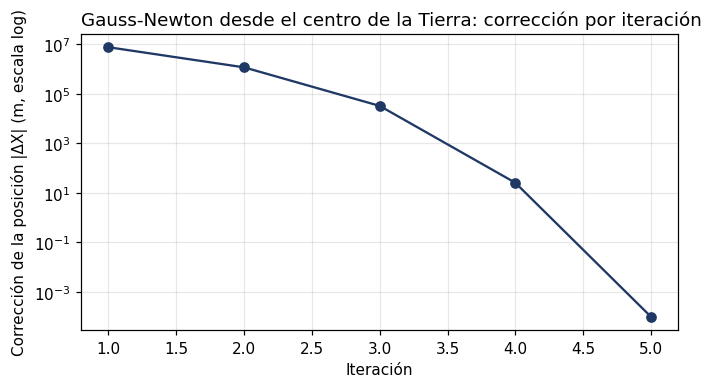

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogy(hist.iteracion, hist.correccion_m.clip(1e-4), "o-", color=AZUL)
ax.set_xlabel("Iteración")
ax.set_ylabel("Corrección de la posición |ΔX| (m, escala log)")
ax.grid(alpha=0.3, which="both")
ax.set_title("Gauss-Newton desde el centro de la Tierra: corrección por iteración", loc="left")

# ¿depende del punto de partida? tres semillas muy distintas
semillas = [(np.zeros(3), "centro de la Tierra"),
            (np.array([1.8e6, -6.15e6, 6.9e5]), "Medellín aproximado"),
            (-rx, "antípoda de Bogotá")]
for semilla, nombre in semillas:
    x_s, _, _, _, h_s = resolver(S, P, x0=np.r_[semilla, 0.0])
    print(f"desde {nombre:<22}: {len(h_s)} iteraciones, misma solución a {np.linalg.norm(x_s[:3] - x[:3]):.4f} m")

Desde el centro de la Tierra, la primera corrección mueve la posición unos 7 581 km; la segunda, 1 168 km; la tercera, 32 km; la cuarta, 26 m, y la quinta, menos de un milímetro. La corrección cae varios órdenes de magnitud por iteración, como en Newton-Raphson (sección 3). Desde tres puntos de partida muy distintos (el centro de la Tierra, cerca de Medellín y el antípoda de Bogotá) se llega a la misma solución en 4 a 6 iteraciones.

## 8. Error de la solución en el sistema local Este-Norte-Arriba

> **Sistema local ENU** — en el punto de la estación: **Este** y **Norte** tangentes al elipsoide, **Arriba** normal a él. El error de una solución se expresa girando la diferencia $(\mathbf{X} - \mathbf{X}_{\text{ref}})$ desde X, Y, Z a este sistema, con la matriz de rotación que depende de la latitud $\varphi$ y la longitud $\lambda$:
> $$\mathbf{R} = \begin{bmatrix} -\sin\lambda & \cos\lambda & 0 \\ -\sin\varphi\cos\lambda & -\sin\varphi\sin\lambda & \cos\varphi \\ \cos\varphi\cos\lambda & \cos\varphi\sin\lambda & \sin\varphi \end{bmatrix}$$


In [11]:
def xyz_a_geodesicas(X, Y, Z, a=6378137.0, f=1/298.257223563):
    """Coordenadas geocéntricas (m) -> latitud y longitud (grados) y altura elipsoidal (m).
    a, f: semieje mayor y aplanamiento del elipsoide (WGS84). Iteración clásica sobre la latitud (igual que en gnss_pseudodistancia)."""
    e2 = f * (2 - f)                       # excentricidad al cuadrado
    lon = np.arctan2(Y, X)                 # la longitud sale directa
    p = np.hypot(X, Y)                     # distancia al eje de rotación
    lat = np.arctan2(Z, p * (1 - e2))      # primera aproximación de la latitud
    for _ in range(10):                    # se refina la latitud (converge en pocas vueltas)
        N = a / np.sqrt(1 - e2 * np.sin(lat) ** 2)     # radio de curvatura en el primer vertical
        h = p / np.cos(lat) - N                         # altura sobre el elipsoide
        lat = np.arctan2(Z, p * (1 - e2 * N / (N + h)))
    return np.degrees(lat), np.degrees(lon), h

la, lo = np.radians(xyz_a_geodesicas(*rx)[:2])
# matriz de rotación de (X, Y, Z) a (Este, Norte, Arriba) en la estación
Rm = np.array([[-np.sin(lo),              np.cos(lo),              0],
               [-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)],
               [ np.cos(la) * np.cos(lo),  np.cos(la) * np.sin(lo), np.sin(la)]])

def enu(x):
    """Error de la solución x respecto a la posición de referencia, en metros hacia el Este, el Norte y Arriba."""
    return Rm @ (x[:3] - rx)

E_, N_, U_ = enu(x)
print(f"error a las 12:00:00: {E_:+.2f} m Este, {N_:+.2f} m Norte, {U_:+.2f} m Arriba | c·δt_R = {x[3]:.2f} m = {x[3]/C*1e9:.0f} ns")


error a las 12:00:00: +0.82 m Este, +0.90 m Norte, +11.34 m Arriba | c·δt_R = 13.00 m = 43 ns


La solución de las 12:00 queda +0,82 m al Este y +0,90 m al Norte de la posición de referencia, y +11,34 m más arriba. El error horizontal es del orden de la exactitud de esa posición aproximada (al metro); el vertical no. El reloj sale $c\,\delta t_R = 13{,}0$ m (43 ns). En `gnss_pseudodistancia.ipynb` (sección 7), con la posición fija, el reloj estimado era de 7,6 m como valor del día, y la mediana de los residuos de esta época, 7,3 m. La diferencia no es un error de cálculo: con la posición libre, la parte de la atmósfera no modelada que cambia con la elevación se reparte entre la altura y el reloj, que están muy correlacionados (0,95 en esta época; sección 11). La sección 9 lo explica.

## 9. Solución en las 2 880 épocas: precisión, sesgo y control de calidad

Repitiendo la solución en cada época se ven la **precisión** (la dispersión de los errores) y el **sesgo** (el error sistemático). Antes hay que revisar los residuos de cada época. La desviación típica estimada de una medida es
$$\hat\sigma_0 = \sqrt{\frac{\mathbf{v}^{\top}\mathbf{v}}{n - 4}}$$
donde $n - 4$ son los grados de libertad: las medidas que sobran después de determinar las cuatro incógnitas. Si en alguna época sale de kilómetros, alguna medida está mal.


In [12]:
filas = []
for t, g in D.groupby("t"):                       # una solución por época
    if len(g) < 4:
        continue                                   # con menos de 4 satélites no hay solución
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    x_, A_, v_, Q_, h_ = resolver(S_, P_)
    e_ = enu(x_)
    sigma0_ = np.sqrt(v_ @ v_ / (len(v_) - 4))    # desviación típica estimada de una medida
    filas.append(dict(t=t, n=len(g), E=e_[0], N=e_[1], U=e_[2], c_dtR=x_[3], sigma0=sigma0_, iteraciones=len(h_)))
sol = pd.DataFrame(filas).set_index("t")

malas = sol[sol.sigma0 > 100]                     # control de calidad: épocas con residuos absurdos
print("épocas con sigma0 > 100 m:", len(malas))
print(malas.round(1))

épocas con sigma0 > 100 m: 1
                      n          E          N          U      c_dtR  \
t                                                                     
2026-09-15 15:35:30  10 -7350422.1  1087656.2 -4131987.1 -5735257.3   

                        sigma0  iteraciones  
t                                            
2026-09-15 15:35:30  5302822.2           15  


In [13]:
t_mala = malas.index[0]
g = D[D.t == t_mala]
r_geom = np.linalg.norm(g[["xs", "ys", "zs"]].values - rx, axis=1)     # distancia geométrica desde la posición de referencia
res = g.P1.values + C * g.dts.values - r_geom                          # P1 + c·δtˢ − r: el residuo de gnss_pseudodistancia (sección 7)
print(pd.DataFrame({"sv": g.sv, "P1 (km)": g.P1 / 1e3, "P1 + c·δtˢ − r (km)": res / 1e3}).round(1).to_string(index=False))
print("\nUna pseudodistancia de 5 353 km es imposible (los satélites GPS están entre 20 000 y 26 000 km): esa época se descarta.")
sol = sol[sol.sigma0 <= 100]

 sv  P1 (km)  P1 + c·δtˢ − r (km)
G10  24233.8                  0.0
G12  23408.5                  0.0
G13  22857.9                  0.0
G18  20243.0                  0.0
G23  21982.9                  0.0
G24  23015.2                  0.0
G25  22143.8                  0.0
G28  22402.1                  0.0
G29  23908.9                  0.0
G32   5353.2             -17987.5

Una pseudodistancia de 5 353 km es imposible (los satélites GPS están entre 20 000 y 26 000 km): esa época se descarta.


Es la misma medida errónea de G32 que trae la tabla de `gnss_pseudodistancia.ipynb`. Allí no afectó la estimación del reloj (sección 7), porque la mediana tolera medidas malas: en esa época, la mediana siguió en el centro de los demás satélites. Los mínimos cuadrados no la toleran: una sola medida mala arrastra la solución de toda la época millones de metros. Por eso los residuos de cada solución se revisan siempre antes de usarla.

2879 épocas | RMS horizontal 2.90 m | error en altura: media +15.4 m, RMS 16.4 m | sigma0 mediana 1.29 m


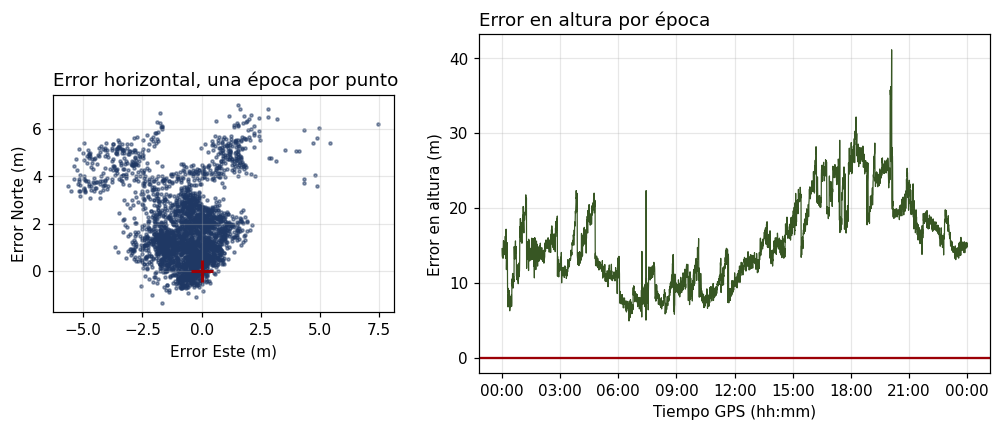

In [14]:
rms_h = np.sqrt((sol.E**2 + sol.N**2).mean())
print(f"{len(sol)} épocas | RMS horizontal {rms_h:.2f} m | error en altura: media {sol.U.mean():+.1f} m, RMS {np.sqrt((sol.U**2).mean()):.1f} m | sigma0 mediana {sol.sigma0.median():.2f} m")

fig, axs = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[1, 1.5]))
axs[0].scatter(sol.E, sol.N, s=4, color=AZUL, alpha=0.5)
axs[0].plot(0, 0, "+", color=ROJO, ms=14, mew=2)
axs[0].set_aspect("equal")
axs[0].set_xlabel("Error Este (m)")
axs[0].set_ylabel("Error Norte (m)")
axs[0].set_title("Error horizontal, una época por punto", loc="left")
axs[0].grid(alpha=0.3)
axs[1].plot(sol.index, sol.U, color=VERDE, lw=0.8)
axs[1].axhline(0, color=ROJO)
axs[1].set_ylabel("Error en altura (m)")
axs[1].set_xlabel("Tiempo GPS (hh:mm)")
axs[1].set_title("Error en altura por época", loc="left")
axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axs[1].grid(alpha=0.3);

In [15]:
# por qué la altura sale arriba: la época de las 12:00, resuelta con un retardo simulado en lugar de las medidas
el_, az_ = np.radians(ep.el.values), np.radians(ep.az.values)
H = np.c_[-np.cos(el_) * np.sin(az_), -np.cos(el_) * np.cos(az_), -np.sin(el_), np.ones(n)]   # matriz de diseño en E, N, U y reloj
for nombre, retardo in [("igual en todos los satélites, 5 m", np.full(n, 5.0)),
                        ("troposférico, 2,3 m / sen(elevación)", 2.3 / np.sin(el_))]:
    dE, dN, dU, d_reloj = np.linalg.lstsq(H, retardo, rcond=None)[0]
    print(f"retardo {nombre:<38} -> E {dE:+.2f}  N {dN:+.2f}  U {dU:+.2f}  c·δt_R {d_reloj:+.2f} m")


retardo igual en todos los satélites, 5 m      -> E +0.00  N -0.00  U -0.00  c·δt_R +5.00 m
retardo troposférico, 2,3 m / sen(elevación)   -> E +0.77  N -0.06  U +8.19  c·δt_R +9.31 m


**Lectura.** El error horizontal (izquierda) se concentra cerca de cero, con un RMS de 2,90 m. Entre las 18:00 y las 22:00 de tiempo GPS (de las 13:00 a las 17:00 en Bogotá) aparece un grupo desplazado unos 3 a 6 m al Norte. El error en altura (derecha) es siempre positivo: entre +5 y +41 m, con media +15,4 m. Es menor de madrugada (unos 8 m hacia las 06:00 GPS, la 01:00 en Bogotá) y mayor por la tarde (unos 25 m entre las 16:00 y las 20:00 GPS): coincide con el ciclo diario de la ionosfera (`gnss_pseudodistancia.ipynb`, sección 10). Las horas del grupo desplazado al Norte coinciden con las de más ionosfera; probablemente, la ionosfera no es igual en todas las direcciones, y esa diferencia entre satélites también mueve la posición horizontal. La desviación típica de una medida, $\hat\sigma_0$, tiene mediana 1,29 m: el ruido es de un metro, pero el error en altura es más de diez veces mayor. No es ruido: es un sesgo.

La celda anterior explica de dónde sale. Resuelve la época de las 12:00 con un retardo simulado en lugar de las medidas. Un retardo igual para todos los satélites lo absorbe entero el reloj, y la posición no cambia. Pero la atmósfera no es igual para todos: crece cuando el satélite baja. Esa parte se parece a subir el receptor: al subir, las distancias a los satélites altos se acortan más que las de los bajos, así que, comparadas, las de los bajos quedan más largas, como si su señal llegara tarde. Con un retardo troposférico de 2,3 m/sen(E), la geometría de las 12:00 da +8,2 m en altura y +9,3 m en el reloj, casi sin mover la posición horizontal. La ionosfera, que en BOGT llega a unos 11 m con el satélite bajo, suma su parte. Por eso un receptor que no corrige la atmósfera se equivoca sobre todo en altura, y hacia arriba.

## 10. Mínimos cuadrados ponderados por elevación

Agrupando los residuos posteriores al ajuste de todas las soluciones del día por elevación, la dispersión crece hacia el horizonte. Tratar todas las medidas por igual es regalar influencia a las peores.

> **Mínimos cuadrados ponderados** — a cada medida se le da un peso $w_i \propto 1/\sigma_i^2$ y se minimiza $\sum w_i v_i^2$. Con $\mathbf{W} = \mathrm{diag}(w_i)$:
> $$\Delta\mathbf{x} = (\mathbf{A}^{\top}\mathbf{W}\mathbf{A})^{-1}\mathbf{A}^{\top}\mathbf{W}\,(\mathbf{O} - \mathbf{C}), \qquad \hat\sigma_0^2 = \frac{\mathbf{v}^{\top}\mathbf{W}\mathbf{v}}{n-4}$$
> Un modelo habitual: $w_i = \operatorname{sen}^2(\text{elevación}_i)$ (cenit, 1; 30°, 0,25; 10°, 0,03).


desviación típica del residuo por franja de elevación (m): {'0-10°': 1.79, '10-20°': 1.44, '20-30°': 1.06, '30-40°': 0.96, '40-50°': 1.13, '50-60°': 0.85, '60-70°': 0.91, '70-80°': 1.16, '80-90°': 1.04}


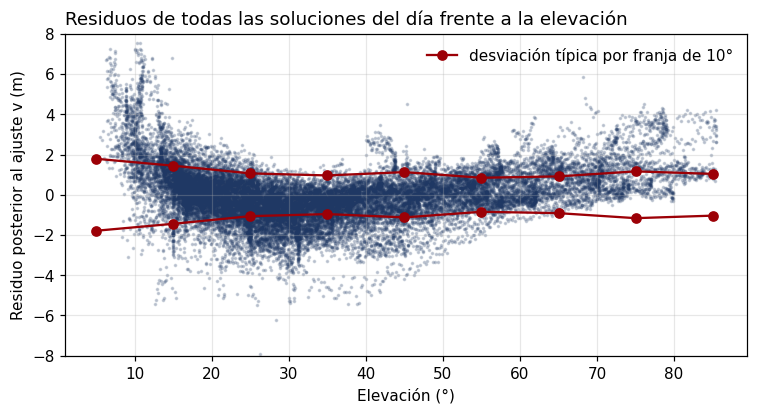

In [16]:
res_el = []                                        # pares (elevación, residuo posterior al ajuste) de todas las soluciones del día
for t, g in D.groupby("t"):
    if len(g) < 5 or t == t_mala:
        continue
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    x_, A_, v_, Q_, h_ = resolver(S_, P_)
    res_el += list(zip(g.el.values, v_))
res_el = np.array(res_el)

# desviación típica de los residuos por franja de 10° de elevación
bins = np.arange(0, 91, 10)
franja = np.digitize(res_el[:, 0], bins)
sd = [res_el[franja == i, 1].std() if (franja == i).sum() > 20 else np.nan for i in range(1, len(bins))]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(res_el[:, 0], res_el[:, 1], s=2, color=AZUL, alpha=0.2)
ax.plot(bins[:-1] + 5, sd, "o-", color=ROJO, label="desviación típica por franja de 10°")
ax.plot(bins[:-1] + 5, -np.array(sd), "o-", color=ROJO)
ax.set_ylim(-8, 8)
ax.set_xlabel("Elevación (°)")
ax.set_ylabel("Residuo posterior al ajuste v (m)")
ax.set_title("Residuos de todas las soluciones del día frente a la elevación", loc="left")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
print("desviación típica del residuo por franja de elevación (m):", {f"{b}-{b+10}°": round(float(s), 2) for b, s in zip(bins[:-1], sd)});

Cada punto es el residuo posterior al ajuste de un satélite en una época, y la línea roja, su desviación típica por franja de 10°. Crece hacia el horizonte: unos 1,8 m por debajo de 10°, 1,4 m entre 10° y 20°, y alrededor de 1 m por encima de 20°. Con el satélite bajo, la señal llega más débil, recorre más atmósfera y sufre más reflexiones cerca de la antena.

In [17]:
W = np.diag(np.sin(np.radians(ep.el.values)) ** 2)      # matriz de pesos: sen²(elevación) en la diagonal
xw, Aw, vw, Qw, hw = resolver(S, P, W=W)
print("pesos:", dict(zip(ep.sv, np.diag(W).round(2).tolist())))
print(f"error 12:00 sin pesos: {enu(x).round(2)} m | con pesos sen²(el): {enu(xw).round(2)} m")

# lo mismo en todo el día
filas = []
for t, g in D.groupby("t"):
    if len(g) < 4 or t == t_mala:
        continue
    S_ = g[["xs", "ys", "zs"]].values
    P_ = g.P1.values + C * g.dts.values
    W_ = np.diag(np.sin(np.radians(g.el.values)) ** 2)
    x_, _, _, _, _ = resolver(S_, P_, W=W_)
    e_ = enu(x_)
    filas.append(dict(t=t, Ew=e_[0], Nw=e_[1], Uw=e_[2]))
solw = pd.DataFrame(filas).set_index("t")

rms_hw = np.sqrt((solw.Ew**2 + solw.Nw**2).mean())
print(f"RMS horizontal del día: sin pesos {rms_h:.2f} m, con pesos {rms_hw:.2f} m | RMS altura: {np.sqrt((sol.U**2).mean()):.1f} -> {np.sqrt((solw.Uw**2).mean()):.1f} m")

pesos: {'G05': 0.14, 'G11': 0.25, 'G12': 0.14, 'G13': 0.11, 'G15': 0.87, 'G20': 0.53, 'G24': 0.42, 'G25': 0.09, 'G29': 0.54}
error 12:00 sin pesos: [ 0.82  0.9  11.34] m | con pesos sen²(el): [0.69 1.19 9.43] m


RMS horizontal del día: sin pesos 2.90 m, con pesos 2.32 m | RMS altura: 16.4 -> 13.3 m


Con pesos $\operatorname{sen}^2(\text{elevación})$, el error de las 12:00 pasa de (+0,82; +0,90; +11,34) m a (+0,69; +1,19; +9,43) m en Este, Norte y Arriba. En todo el día, el RMS horizontal baja de 2,90 a 2,32 m, y el de altura, de 16,4 a 13,3 m: los satélites bajos, con más ruido y más atmósfera, pesan menos en la solución.

## 11. Propagación de la incertidumbre: covarianza de la solución

> Si cada medida tiene un error aleatorio de desviación típica $\sigma_0$, la solución hereda una incertidumbre que se **calcula**, no se supone:
> $$\boldsymbol{\Sigma}_{\mathbf{x}} = \sigma_0^2\,(\mathbf{A}^{\top}\mathbf{W}\mathbf{A})^{-1} = \sigma_0^2\,\mathbf{Q}$$
> $\mathbf{Q}$ es la **matriz cofactor**: depende solo de la geometría. La diagonal de $\boldsymbol{\Sigma}$ son las varianzas de $X, Y, Z$ y $c\,\delta t_R$; fuera de la diagonal, las covarianzas, que divididas por las desviaciones típicas dan las **correlaciones** entre incógnitas. Girada a ENU, da $\sigma_E, \sigma_N, \sigma_U$ y la **elipse de error** horizontal.


sigma0 = 0.82 m
Q_ENU =
 [[ 0.574 -0.127  0.121  0.057]
 [-0.127  0.355 -0.501 -0.309]
 [ 0.121 -0.501  3.26   1.838]
 [ 0.057 -0.309  1.838  1.15 ]]
σ_E, σ_N, σ_U, σ_c·δt_R = [0.62 0.49 1.48 0.88] m
correlación entre la altura y el reloj: 0.95
posición de referencia a 2.7 σ en horizontal | error en altura +11.34 m = 7.7 σ_U


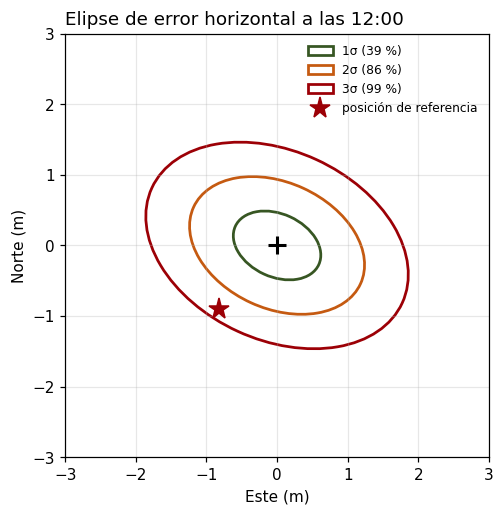

In [18]:
def covarianza_enu(Q):
    """Gira la matriz cofactor Q (en X, Y, Z, c·δt_R) al sistema local (E, N, U, c·δt_R)."""
    T = np.block([[Rm, np.zeros((3, 1))],
                  [np.zeros((1, 3)), np.ones((1, 1))]])
    return T @ Q @ T.T

sigma0 = np.sqrt(v @ v / (n - 4))        # desviación típica estimada de una medida (n − 4 grados de libertad)
Qenu = covarianza_enu(Q)
Sigma = sigma0**2 * Qenu                  # matriz de covarianza de la solución
print(f"sigma0 = {sigma0:.2f} m")
print("Q_ENU =\n", Qenu.round(3))
print("σ_E, σ_N, σ_U, σ_c·δt_R =", np.sqrt(np.diag(Sigma)).round(2), "m")
print(f"correlación entre la altura y el reloj: {Qenu[2, 3] / np.sqrt(Qenu[2, 2] * Qenu[3, 3]):.2f}")
d_elipse = np.sqrt(np.array([E_, N_]) @ np.linalg.inv(Sigma[:2, :2]) @ np.array([E_, N_]))   # distancia a la referencia en unidades de σ
print(f"posición de referencia a {d_elipse:.1f} σ en horizontal | error en altura {U_:+.2f} m = {U_ / np.sqrt(Sigma[2, 2]):.1f} σ_U")

# elipse de error horizontal: ejes = raíces de los autovalores del bloque E-N; orientación = autovector
from matplotlib.patches import Ellipse
autoval, autovec = np.linalg.eigh(Sigma[:2, :2])
angulo = np.degrees(np.arctan2(autovec[1, 1], autovec[0, 1]))
fig, ax = plt.subplots(figsize=(5, 5))
ax.set_aspect("equal")
for k, color, etiqueta in [(1, VERDE, "1σ (39 %)"), (2, NARANJA, "2σ (86 %)"), (3, ROJO, "3σ (99 %)")]:
    ax.add_patch(Ellipse((0, 0), 2 * k * np.sqrt(autoval[1]), 2 * k * np.sqrt(autoval[0]), angle=angulo, fill=False, ec=color, lw=1.8, label=etiqueta))
ax.plot(0, 0, "+", color="k", ms=12, mew=2)                       # la solución
ax.plot(-E_, -N_, "*", color=ROJO, ms=14, label="posición de referencia")
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_xlabel("Este (m)"); ax.set_ylabel("Norte (m)")
ax.legend(fontsize=8, frameon=False)
ax.grid(alpha=0.3)
ax.set_title("Elipse de error horizontal a las 12:00", loc="left");

A las 12:00, $\hat\sigma_0 = 0{,}82$ m, y las desviaciones típicas de la solución son $\sigma_E = 0{,}62$ m, $\sigma_N = 0{,}49$ m y $\sigma_U = 1{,}48$ m: la altura queda entre dos y tres veces peor determinada que la horizontal. La elipse está inclinada porque los errores en Este y Norte están correlacionados. La posición de referencia (estrella) queda a 2,7 σ de la solución, entre las elipses de 2σ y 3σ: compatible con el ruido, más aún considerando que esa posición es aproximada. La altura no: el error de +11,34 m equivale a 7,7 $\sigma_U$. La covarianza describe solo el ruido aleatorio, y el sesgo de la atmósfera no está en ella. La correlación de 0,95 entre la altura y el reloj explica por qué los dos se mueven juntos (secciones 8 y 9).

## 12. Dilución de la precisión (DOP)

> **Dilución de la precisión (DOP)** — como $\boldsymbol{\Sigma} = \sigma_0^2\mathbf{Q}$, la incertidumbre de la posición es la de una medida multiplicada por un factor que solo depende de la geometría. Con $q$ los elementos de la diagonal de $\mathbf{Q}_{ENU}$ ($q_{tt}$, el del reloj):
> $$\text{GDOP} = \sqrt{q_{EE}+q_{NN}+q_{UU}+q_{tt}},\quad \text{PDOP} = \sqrt{q_{EE}+q_{NN}+q_{UU}},\quad \text{HDOP} = \sqrt{q_{EE}+q_{NN}},\quad \text{VDOP} = \sqrt{q_{UU}},\quad \text{TDOP} = \sqrt{q_{tt}}$$
> No tiene unidades. Se calcula **antes de medir**, solo con las posiciones de los satélites; el DOP crece cuando los satélites se agrupan y se dispara cuando quedan casi en un plano.


In [19]:
def dops(Q):
    """Diluciones de la precisión a partir de la matriz cofactor Q (en X, Y, Z, c·δt_R)."""
    q = np.diag(covarianza_enu(Q))       # varianzas cofactor en E, N, U y c·δt_R
    return dict(GDOP=np.sqrt(q.sum()),
                PDOP=np.sqrt(q[:3].sum()),
                HDOP=np.sqrt(q[:2].sum()),
                VDOP=np.sqrt(q[2]),
                TDOP=np.sqrt(q[3]))

d = dops(Q)
print({k: round(float(valor), 2) for k, valor in d.items()})
print(f"incertidumbre esperada: horizontal HDOP·σ0 = {d['HDOP']*sigma0:.2f} m, vertical VDOP·σ0 = {d['VDOP']*sigma0:.2f} m")

{'GDOP': 2.31, 'PDOP': 2.05, 'HDOP': 0.96, 'VDOP': 1.81, 'TDOP': 1.07}
incertidumbre esperada: horizontal HDOP·σ0 = 0.79 m, vertical VDOP·σ0 = 1.48 m


mejor PDOP 1.42 a las 20:06 (10 satélites) | peor PDOP 2.87 a las 00:23 (7 satélites)


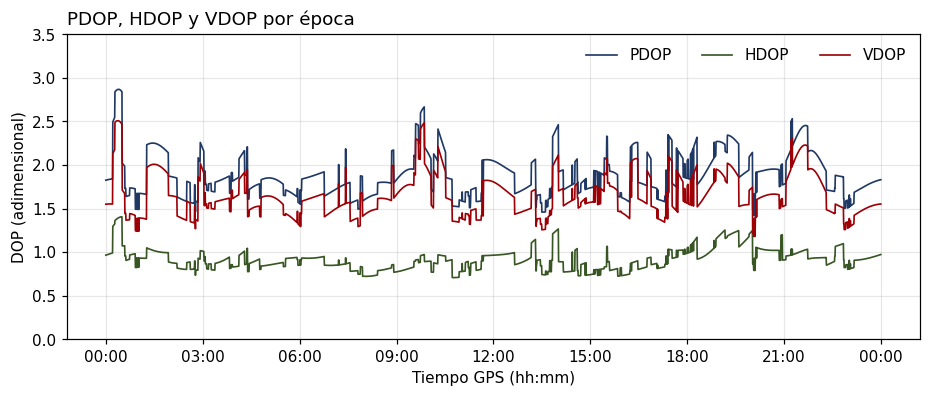

In [20]:
# el DOP solo necesita la geometría: se calcula con A en la posición de referencia, sin resolver nada
filas = []
for t, g in D.groupby("t"):
    if len(g) < 4 or t == t_mala:
        continue
    A_, _ = diseno(np.r_[rx, 0.0], g[["xs", "ys", "zs"]].values, g.P1.values)
    d_ = dops(np.linalg.inv(A_.T @ A_))
    d_["t"] = t
    d_["n"] = len(g)
    filas.append(d_)
dop = pd.DataFrame(filas).set_index("t")

fig, ax = plt.subplots(figsize=(10, 3.6))
for nombre, color in [("PDOP", AZUL), ("HDOP", VERDE), ("VDOP", ROJO)]:
    ax.plot(dop.index, dop[nombre], lw=1.1, label=nombre, color=color)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.set_ylim(0, 3.5)
ax.set_xlabel("Tiempo GPS (hh:mm)")
ax.set_ylabel("DOP (adimensional)")
ax.legend(ncol=3, frameon=False)
ax.grid(alpha=0.3)
ax.set_title("PDOP, HDOP y VDOP por época", loc="left")

t_mejor, t_peor = dop.PDOP.idxmin(), dop.PDOP.idxmax()
print(f"mejor PDOP {dop.PDOP.min():.2f} a las {t_mejor.strftime('%H:%M')} ({dop.loc[t_mejor, 'n']} satélites) | peor PDOP {dop.PDOP.max():.2f} a las {t_peor.strftime('%H:%M')} ({dop.loc[t_peor, 'n']} satélites)")

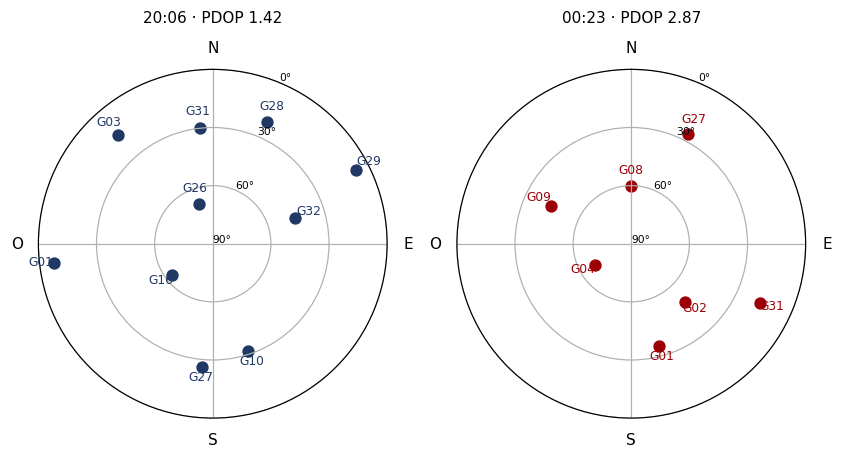

In [21]:
def cielo(ax, g, color, titulo):
    """Dibuja el cielo (acimut y elevación) de los satélites de una época en un eje polar."""
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_rlim(0, 90)
    ax.set_yticks([0, 30, 60, 90]); ax.set_yticklabels(["90°", "60°", "30°", "0°"], fontsize=7)
    ax.set_xticks(np.radians([0, 90, 180, 270])); ax.set_xticklabels(["N", "E", "S", "O"])
    ax.scatter(np.radians(g.az), 90 - g.el, s=50, color=color)     # el radio es 90° − elevación: el cenit queda en el centro
    for az_, el_, sv_ in zip(g.az, g.el, g.sv):
        ax.text(np.radians(az_), 90 - el_ + 7, sv_, ha="center", fontsize=8, color=color)
    ax.set_title(titulo, fontsize=10, pad=12)

fig = plt.figure(figsize=(9, 4.3))
for k, (t_, color) in enumerate([(t_mejor, AZUL), (t_peor, ROJO)]):
    cielo(fig.add_subplot(1, 2, k + 1, projection="polar"), D[D.t == t_], color, f"{t_.strftime('%H:%M')} · PDOP {dop.loc[t_, 'PDOP']:.2f}")

En el día, el PDOP va de 1,42 a 2,87; el HDOP se mantiene cerca de 1, y el VDOP es casi siempre mayor: la geometría determina peor la altura, porque todos los satélites están por encima del horizonte. El mejor PDOP (20:06, diez satélites) corresponde a un cielo con satélites repartidos en todas las direcciones y elevaciones; el peor (00:23, siete satélites), a un cielo con varios satélites cerca del cenit y pocos cerca del horizonte. A las 20:06, la hora del mejor PDOP, se da también el mayor error en altura del día (+41 m, sección 9): el DOP describe la geometría, no la atmósfera.

## 13. Efecto de la geometría: selección de satélites

Con nueve satélites hay 126 maneras de quedarse con cuatro. El mejor cuarteto (uno alto y tres bajos repartidos) tiene un GDOP parecido al de los nueve; el peor deja los cuatro casi en un plano y la matriz $\mathbf{A}^{\top}\mathbf{A}$ cerca de ser singular: con las mismas medidas, el error llega a cientos de metros.

Quitar los satélites bajos empeora el DOP (sobre todo el VDOP) y, sin embargo, puede reducir el error real en altura. El DOP amplifica el **ruido aleatorio**, pero los satélites bajos traen además el mayor **retardo atmosférico**, un sesgo que el DOP no ve y que sube la solución (sección 9). Por eso los receptores usan una **máscara de elevación** (típicamente de 5 a 15°) y corrigen la atmósfera con modelos.


In [22]:
import itertools
cuartetos = []
for idx in itertools.combinations(range(n), 4):        # todas las maneras de elegir 4 de los n satélites
    idx = list(idx)
    try:
        x4, A4, v4, Q4, _ = resolver(S[idx], P[idx])
        cuartetos.append(dict(svs=" ".join(ep.sv[idx]), GDOP=dops(Q4)["GDOP"], error_3D=np.linalg.norm(enu(x4))))
    except np.linalg.LinAlgError:                       # geometría singular: no hay solución
        pass
cu = pd.DataFrame(cuartetos).sort_values("GDOP")
print("mejor cuarteto:\n", cu.head(3).round(1).to_string(index=False))
print("\npeor cuarteto:\n", cu.tail(3).round(1).to_string(index=False))
print("\nGDOP mediano de los", len(cu), "cuartetos:", round(cu.GDOP.median(), 1))

mejor cuarteto:
             svs  GDOP  error_3D
G05 G11 G15 G25   2.8      10.1
G05 G15 G24 G25   2.9      10.6
G05 G11 G13 G15   3.2       9.1

peor cuarteto:
             svs  GDOP  error_3D
G12 G15 G24 G25 451.1      14.0
G05 G12 G13 G29 623.5      84.2
G05 G11 G12 G25 641.3     421.2

GDOP mediano de los 126 cuartetos: 6.7


In [23]:
casos = [("los nueve", np.ones(n, bool)),
         ("solo elevación > 25°", ep.el.values > 25),
         ("solo elevación > 40°", ep.el.values > 40)]
for nombre, mascara in casos:
    idx = np.where(mascara)[0]
    xq, Aq, vq, Qq, _ = resolver(S[idx], P[idx])
    dq = dops(Qq)
    print(f"{nombre:<22} n={len(idx)}  HDOP {dq['HDOP']:.2f}  VDOP {dq['VDOP']:.2f}  error E,N,U = {enu(xq).round(1)} m")

los nueve              n=9  HDOP 0.96  VDOP 1.81  error E,N,U = [ 0.8  0.9 11.3] m
solo elevación > 25°   n=5  HDOP 1.80  VDOP 5.21  error E,N,U = [-0.6  1.2  5.9] m
solo elevación > 40°   n=4  HDOP 2.05  VDOP 5.74  error E,N,U = [0.5 1.5 2.8] m


Con los nueve satélites, el VDOP es 1,81 y el error en altura +11,3 m. Al quedarse solo con los satélites por encima de 40°, el VDOP sube a 5,74, pero el error en altura baja a +2,8 m. El DOP predice que la altura empeora, y con ruido aleatorio así sería; pero aquí el error dominante es el sesgo de la atmósfera, que es mayor en los satélites bajos (sección 9): quitarlos quita sesgo aunque empeore la geometría. En el otro extremo, el peor cuarteto (GDOP 641) da 421 m de error con las mismas medidas: allí sí manda la geometría.

## 14. Contenido mínimo del reporte de una solución

Una posición sin su incertidumbre no es un resultado. El reporte mínimo de una época:


In [24]:
reporte = {
    "época (tiempo GPS)": str(t0),
    "satélites usados": list(ep.sv),
    "pesos": "iguales",
    "X, Y, Z (m)": x[:3].round(3).tolist(),
    "c·δt_R (m)": round(x[3], 3),
    "sigma0 (m)": round(sigma0, 3),
    "residuos (m)": v.round(2).tolist(),
    "σ_E, σ_N, σ_U (m)": np.sqrt(np.diag(Sigma))[:3].round(2).tolist(),
    **{k: round(float(valor), 2) for k, valor in d.items()},
    "error respecto a la posición de referencia E, N, U (m)": enu(x).round(2).tolist(),
    "correcciones aplicadas": "reloj del satélite (af0, af1, af2, relativista, T_GD); instante de emisión con P1; atmósfera: ninguna",
}
for clave, valor in reporte.items():
    print(f"{clave:<52} {valor}")

época (tiempo GPS)                                   2026-09-15 12:00:00
satélites usados                                     ['G05', 'G11', 'G12', 'G13', 'G15', 'G20', 'G24', 'G25', 'G29']
pesos                                                iguales
X, Y, Z (m)                                          [1744402.911, -6116048.132, 512733.571]
c·δt_R (m)                                           12.998
sigma0 (m)                                           0.818
residuos (m)                                         [0.09, 0.57, -0.19, -0.28, 1.11, -0.69, -0.5, 0.63, -0.74]
σ_E, σ_N, σ_U (m)                                    [0.62, 0.49, 1.48]
GDOP                                                 2.31
PDOP                                                 2.05
HDOP                                                 0.96
VDOP                                                 1.81
TDOP                                                 1.07
error respecto a la posición de referencia E, N, U (m) [0.82, 0

## 15. Ejercicios para clase

Elija una época distinta de las 12:00:00 y escríbala en la celda siguiente. Dos sugerencias: las **06:00:00**, de madrugada, con poca ionosfera, y las **20:06:00**, por la tarde, con mucha. Cada pregunta se responde con una o dos cifras y una frase; la pista dice qué función usar y qué sección consultar.

In [25]:
# ── ejercicios: cambie la hora ──
t_ej = pd.Timestamp("2026-09-15 06:00:00")
ep_ej = D[D.t == t_ej].sort_values("sv").reset_index(drop=True)
S_ej = ep_ej[["xs", "ys", "zs"]].values           # posiciones de los satélites (m)
P_ej = ep_ej.P1.values + C * ep_ej.dts.values     # medidas corregidas P1 + c·δtˢ (m)
ep_ej[["sv", "el", "az"]].round(1)

,sv,el,az
0,G03,10.2,40.9
1,G06,50.4,313.5
2,G07,9.9,157.6
3,G09,15.8,125.3
4,G11,36.9,263.7
5,G14,73.4,82.7
6,G17,28.9,20.1
7,G19,24.4,341.8
8,G21,26.0,200.9
9,G22,65.5,11.8


1. **Los datos.** ¿Cuántos satélites hay en la época? ¿Cuántos grados de libertad quedan ($n - 4$)? ¿Cuál es el satélite más bajo y a qué elevación está?
   *Pista: la tabla de la celda anterior; sección 9.*
2. **La solución.** Resuelva con `x_ej, A_ej, v_ej, Q_ej, h_ej = resolver(S_ej, P_ej)`. ¿Cuántas iteraciones necesitó (`len(h_ej)`)? ¿Cuál es el error Este, Norte y Arriba (`enu(x_ej)`)? ¿Qué componente es la mayor, y por qué?
   *Pista: secciones 7, 8 y 9.*
3. **El reloj.** ¿Cuánto vale $c\,\delta t_R$ (`x_ej[3]`)? Compárelo con los 13,0 m de las 12:00. Si el reloj de BOGT es estable (`gnss_pseudodistancia.ipynb`, sección 7), ¿por qué cambia?
   *Pista: sección 9 y la correlación entre la altura y el reloj de la sección 11.*
4. **La geometría.** Calcule `dops(Q_ej)`. ¿Cuál es mayor, el HDOP o el VDOP? ¿Por qué?
   *Pista: sección 12.*
5. **Quitar el satélite más bajo.** Resuelva de nuevo sin él:
   `idx = (ep_ej.el != ep_ej.el.min()).values` y `resolver(S_ej[idx], P_ej[idx])`. ¿Qué pasa con el VDOP? ¿Y con el error en altura? ¿Mejora o empeora la solución?
   *Pista: sección 13.*
6. **Una medida mala.** Sume 300 m a la medida del satélite más alto y resuelva:
   `P_mala = P_ej.copy()`, `P_mala[ep_ej.el.idxmax()] += 300` y `resolver(S_ej, P_mala)`. ¿Qué satélite tiene el residuo más grande? ¿Los residuos de los demás quedan cerca de cero? ¿Cuánto se movió la posición?
   *Pista: sección 9 (control de calidad) y `gnss_pseudodistancia.ipynb`, sección 7 (por qué la mediana no se deja arrastrar).*

**Para quien termine antes:** repita la pregunta 2 con pesos $\operatorname{sen}^2(\text{elevación})$ (sección 10) y compare el error en altura.

## Referencias

- Blewitt, G. (1997). *Basics of the GPS Technique: Observation Equations, Software Developments, and Data Processing*. En Teunissen y Kleusberg (eds.), GPS for Geodesy. Springer.
- Leick, A., Rapoport, L. y Tatarnikov, D. (2015). *GPS Satellite Surveying*, 4.ª ed. Wiley.
- Groves, P. D. (2013). *Principles of GNSS, Inertial, and Multisensor Integrated Navigation Systems*, 2.ª ed. Artech House.
- IS-GPS-200, *Navstar GPS Space Segment/Navigation User Segment Interfaces* (gps.gov/technical/icwg).
- Legendre, A.-M. (1805). *Nouvelles méthodes pour la détermination des orbites des comètes* · Gauss, C. F. (1809). *Theoria motus corporum coelestium*.
- IGS, International GNSS Service (igs.org): datos de la estación BOGT.
- `gnss_pseudodistancia.ipynb` (este curso): la ecuación de la pseudodistancia, sus términos y la tabla de datos que usa este cuaderno.